# Preliminary YOLOv8n Training for Assistive Navigation

**Study:** Development of a Mobile Assistive Navigation Prototype for Visually Impaired Users  
**Purpose:** Produce a reproducible pilot experiment for obstacle detection before full campus-data collection.

> **Research-integrity note:** This is a five-epoch pilot on a bounded subset. Its measurements are preliminary pipeline evidence, not the final accuracy of the proposed system and not evidence of real-world navigation safety.

## 1. Experiment question and flow

The experiment asks whether a compact YOLOv8n detector can be fine-tuned to recognize seven obstacles relevant to mixed indoor/outdoor campus navigation. The notebook performs environment verification, deterministic data selection, label validation, a pretrained baseline on compatible classes, five-epoch fine-tuning, metric reporting, and visual prediction review.

The seven pilot classes are **person, chair, stairs, car, bicycle, electrical pole, and plant pot**. The final thesis taxonomy will later add locally collected categories such as doors and tables.

In [1]:
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime
import hashlib, json, os, platform, random, shutil, sys, time

PROJECT_ROOT = next((path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (path / 'notebooks' / '01_yolov8n_training_pilot.ipynb').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook from inside the thesis workspace.')

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
import yaml
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage
from ultralytics import YOLO, __version__ as ultralytics_version, settings as ultralytics_settings
ultralytics_settings['wandb'] = False  # keep the local pilot offline and non-interactive

DATA_ROOT = PROJECT_ROOT / 'data'
METADATA_ROOT = DATA_ROOT / 'source' / 'rod_metadata'
PILOT_ROOT = DATA_ROOT / 'processed' / 'rod_pilot_7class'
RUNS_ROOT = PROJECT_ROOT / 'runs' / 'yolov8n_pilot'
for path in [METADATA_ROOT, PILOT_ROOT, RUNS_ROOT]:
    path.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

environment = {
    'timestamp': datetime.now().astimezone().isoformat(),
    'python': sys.version.split()[0],
    'platform': platform.platform(),
    'torch': torch.__version__,
    'ultralytics': ultralytics_version,
    'cuda_available': torch.cuda.is_available(),
    'cuda_runtime': torch.version.cuda,
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
    'seed': SEED,
}
display(pd.Series(environment, name='value').to_frame())

,value
timestamp,2026-09-03T18:04:43.082820+08:00
python,3.10.0
platform,Windows-10-10.0.26200-SP0
torch,2.0.1+cu118
ultralytics,8.3.0
cuda_available,True
cuda_runtime,11.8
gpu,NVIDIA GeForce RTX 3050 Laptop GPU
seed,42


## 2. Dataset source and responsible use

The pilot uses the **ROD Dataset: Real-Time Obstacle Detection for Smartphone-Based Assistive Vision**, hosted on Hugging Face. Its data card reports 24,326 images, 40,195 boxes, 25 classes, and predefined train/validation/test splits. The repository declares an MIT release while noting that aggregated Roboflow sources retain their original licenses. Therefore, this pilot records source provenance and does not redistribute the downloaded images.

Source: https://huggingface.co/datasets/Abtinzandi/Obstacle-Detection-Dataset-YOLO  
Accessed: 3 September 2026

The subset preserves the source train/validation boundary. It does not use the test split, which remains reserved for later confirmation.

In [2]:
PARQUET_URLS = {
    'train': 'https://huggingface.co/datasets/Abtinzandi/Obstacle-Detection-Dataset-YOLO/resolve/refs%2Fconvert%2Fparquet/default/train/0000.parquet',
    'validation': 'https://huggingface.co/datasets/Abtinzandi/Obstacle-Detection-Dataset-YOLO/resolve/refs%2Fconvert%2Fparquet/default/validation/0000.parquet',
}

def download_file(url, destination, timeout=120):
    destination = Path(destination)
    if destination.exists() and destination.stat().st_size > 0:
        return destination
    response = requests.get(url, timeout=timeout)
    response.raise_for_status()
    destination.write_bytes(response.content)
    return destination

for split, url in PARQUET_URLS.items():
    download_file(url, METADATA_ROOT / f'{split}.parquet')

source_frames = {s: pd.read_parquet(METADATA_ROOT / f'{s}.parquet') for s in PARQUET_URLS}
pd.DataFrame({s: {'source_images': len(df)} for s, df in source_frames.items()}).T

,source_images
train,19186
validation,3511


## 3. Deterministic pilot selection and label mapping

The notebook chooses 2,000 source-training images and initially over-selects 450 source-validation candidates. It removes exact cross-split duplicates by SHA-256, then deterministically retains 400 clean validation images. It first samples examples for every target class, then fills remaining positions from eligible images using seed 42. Only target-class boxes are retained, and their original IDs are remapped to a continuous seven-class YOLO taxonomy.

In [3]:
TARGET_CLASSES = {
    3: 'person', 23: 'chair', 4: 'stairs', 2: 'car',
    0: 'bicycle', 6: 'electrical_pole', 21: 'plant_pot',
}
OLD_TO_NEW = {old_id: new_id for new_id, old_id in enumerate(TARGET_CLASSES)}
CLASS_NAMES = [TARGET_CLASSES[old_id] for old_id in TARGET_CLASSES]

def parse_boxes(raw):
    boxes = json.loads(raw) if isinstance(raw, str) else (raw or [])
    return [b for b in boxes if int(b['class_id']) in TARGET_CLASSES]

def prepare_frame(df):
    out = df.copy()
    out['target_boxes'] = out['bboxes_yolo'].map(parse_boxes)
    out['target_ids'] = out['target_boxes'].map(lambda boxes: sorted({int(b['class_id']) for b in boxes}))
    return out[out['target_ids'].map(bool)].copy()

def balanced_subset(df, total, minimum_per_class, seed):
    rng = random.Random(seed)
    selected = set()
    for class_id in TARGET_CLASSES:
        candidates = [idx for idx, ids in df['target_ids'].items() if class_id in ids and idx not in selected]
        rng.shuffle(candidates)
        selected.update(candidates[:minimum_per_class])
    remaining = [idx for idx in df.index if idx not in selected]
    rng.shuffle(remaining)
    selected.update(remaining[:max(0, total - len(selected))])
    chosen = list(selected)[:total]
    rng.shuffle(chosen)
    return df.loc[chosen].copy().reset_index(drop=True)

eligible = {s: prepare_frame(df) for s, df in source_frames.items()}
pilot_frames = {
    'train': balanced_subset(eligible['train'], 2000, 220, SEED),
    'val': balanced_subset(eligible['validation'], 450, 25, SEED + 1),
}

def image_class_counts(df):
    counts = Counter(cid for ids in df['target_ids'] for cid in ids)
    return {TARGET_CLASSES[cid]: counts[cid] for cid in TARGET_CLASSES}

distribution = pd.DataFrame({split: image_class_counts(df) for split, df in pilot_frames.items()}).fillna(0).astype(int)
display(distribution)
assert len(pilot_frames['train']) == 2000 and len(pilot_frames['val']) == 450
assert (distribution > 0).all().all()

,train,val
person,389,78
chair,289,94
stairs,250,57
car,412,127
bicycle,222,41
electrical_pole,242,31
plant_pot,238,25


In [4]:
HF_BASE = 'https://huggingface.co/datasets/Abtinzandi/Obstacle-Detection-Dataset-YOLO/resolve/main'
SOURCE_SPLIT_FOLDER = {'train': 'train', 'val': 'valid'}

def write_remapped_label(row, destination):
    lines = []
    for box in row.target_boxes:
        values = [box['x_center'], box['y_center'], box['width'], box['height']]
        if not all(0 <= float(v) <= 1 for v in values):
            continue
        lines.append(f"{OLD_TO_NEW[int(box['class_id'])]} " + ' '.join(f'{float(v):.8f}' for v in values))
    destination.write_text('\n'.join(lines) + '\n', encoding='utf-8')

def fetch_image(task):
    split, row_dict = task
    row = pd.Series(row_dict)
    file_name = Path(row.file_name).name
    image_dest = PILOT_ROOT / 'images' / split / file_name
    label_dest = PILOT_ROOT / 'labels' / split / f'{Path(file_name).stem}.txt'
    image_dest.parent.mkdir(parents=True, exist_ok=True)
    label_dest.parent.mkdir(parents=True, exist_ok=True)
    remote_path = row.file_name.replace('\\', '/')
    url = f"{HF_BASE}/{SOURCE_SPLIT_FOLDER[split]}/{remote_path}"
    if not image_dest.exists() or image_dest.stat().st_size == 0:
        last_error = None
        for attempt in range(4):
            try:
                response = requests.get(url, timeout=90)
                response.raise_for_status()
                image_dest.write_bytes(response.content)
                break
            except Exception as exc:
                last_error = exc; time.sleep(1.5 * (attempt + 1))
        else:
            return str(image_dest), str(last_error)
    write_remapped_label(row, label_dest)
    return str(image_dest), None

tasks = [(split, row._asdict()) for split, df in pilot_frames.items() for row in df.itertuples(index=False)]
failures = []
with ThreadPoolExecutor(max_workers=16) as pool:
    futures = [pool.submit(fetch_image, task) for task in tasks]
    for number, future in enumerate(as_completed(futures), 1):
        path, error = future.result()
        if error: failures.append((path, error))
        if number % 250 == 0 or number == len(futures):
            print(f'Downloaded/checked {number}/{len(futures)}; failures={len(failures)}')
assert not failures, f'Download failures: {failures[:5]}'

Downloaded/checked 250/2450; failures=0


Downloaded/checked 500/2450; failures=0


Downloaded/checked 750/2450; failures=0


Downloaded/checked 1000/2450; failures=0


Downloaded/checked 1250/2450; failures=0


Downloaded/checked 1500/2450; failures=0
Downloaded/checked 1750/2450; failures=0


Downloaded/checked 2000/2450; failures=0


Downloaded/checked 2250/2450; failures=0


Downloaded/checked 2450/2450; failures=0


## 4. Dataset quality checks

Before training, every image must open successfully, have a matching label file, contain at least one valid target box, and remain exclusive to its original split. The following checks prevent a successful-looking run from hiding broken data.

In [5]:
train_hash_lookup = {}
for path in (PILOT_ROOT / 'images' / 'train').glob('*.jpg'):
    train_hash_lookup[hashlib.sha256(path.read_bytes()).hexdigest()] = path.name
unique_val_indices = []
leakage_rows = []
for idx, row in pilot_frames['val'].iterrows():
    path = PILOT_ROOT / 'images' / 'val' / Path(row.file_name).name
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest in train_hash_lookup:
        leakage_rows.append({'validation_image': path.name, 'matching_train_image': train_hash_lookup[digest], 'sha256': digest})
    else:
        unique_val_indices.append(idx)
clean_val_candidates = pilot_frames['val'].loc[unique_val_indices].copy()
pilot_frames['val'] = balanced_subset(clean_val_candidates, 400, 20, SEED + 2)
retained_val_stems = {Path(name).stem for name in pilot_frames['val']['file_name']}
for path in (PILOT_ROOT / 'images' / 'val').glob('*.jpg'):
    if path.stem not in retained_val_stems:
        path.unlink(); label = PILOT_ROOT / 'labels' / 'val' / f'{path.stem}.txt'
        if label.exists(): label.unlink()
leakage_report = pd.DataFrame(leakage_rows, columns=['validation_image', 'matching_train_image', 'sha256'])
leakage_report.to_csv(PILOT_ROOT / 'removed_cross_split_duplicates.csv', index=False)
print(f'Removed {len(leakage_report)} exact cross-split duplicate(s); retained 400 validation images.')

distribution = pd.DataFrame({split: image_class_counts(df) for split, df in pilot_frames.items()}).fillna(0).astype(int)
display(distribution)
assert len(pilot_frames['val']) == 400 and (distribution > 0).all().all()

quality_rows = []
hashes_by_split = {}
for split in ['train', 'val']:
    images = sorted((PILOT_ROOT / 'images' / split).glob('*.jpg'))
    labels = sorted((PILOT_ROOT / 'labels' / split).glob('*.txt'))
    invalid_images = 0; invalid_labels = 0; class_boxes = Counter(); hashes = set()
    for image_path in images:
        raw = image_path.read_bytes(); hashes.add(hashlib.sha256(raw).hexdigest())
        if cv2.imread(str(image_path)) is None: invalid_images += 1
        label_path = PILOT_ROOT / 'labels' / split / f'{image_path.stem}.txt'
        lines = [line.split() for line in label_path.read_text(encoding='utf-8').splitlines() if line.strip()]
        if not lines: invalid_labels += 1
        for fields in lines:
            if len(fields) != 5 or not 0 <= int(fields[0]) < len(CLASS_NAMES): invalid_labels += 1
            else: class_boxes[CLASS_NAMES[int(fields[0])]] += 1
    hashes_by_split[split] = hashes
    quality_rows.append({'split': split, 'images': len(images), 'labels': len(labels), 'invalid_images': invalid_images, 'invalid_labels': invalid_labels, **class_boxes})
quality = pd.DataFrame(quality_rows).set_index('split').fillna(0).astype(int)
display(quality)
assert quality.loc['train', 'images'] == 2000 and quality.loc['val', 'images'] == 400
assert quality[['invalid_images', 'invalid_labels']].to_numpy().sum() == 0
assert hashes_by_split['train'].isdisjoint(hashes_by_split['val']), 'Exact image leakage detected across splits'

dataset_yaml = {
    'path': PILOT_ROOT.as_posix(), 'train': 'images/train', 'val': 'images/val',
    'names': {i: name for i, name in enumerate(CLASS_NAMES)},
}
dataset_yaml_path = PILOT_ROOT / 'dataset.yaml'
dataset_yaml_path.write_text(yaml.safe_dump(dataset_yaml, sort_keys=False), encoding='utf-8')
quality.to_csv(PILOT_ROOT / 'quality_report.csv')
distribution.to_csv(PILOT_ROOT / 'image_class_distribution.csv')
print(dataset_yaml_path.read_text())

Removed 0 exact cross-split duplicate(s); retained 400 validation images.


,train,val
person,389,71
chair,289,81
stairs,250,51
car,412,109
bicycle,222,38
electrical_pole,242,28
plant_pot,238,25


,images,labels,invalid_images,invalid_labels,car,plant_pot,person,bicycle,chair,stairs,electrical_pole
split,,,,,,,,,,,
train,2000,2000,0,0,654,302,1198,236,452,358,246
val,400,400,0,0,188,37,148,43,113,70,29


path: C:/Users/User/Documents/first_year_files/THIRD_YEAR/THESIS/data/processed/rod_pilot_7class
train: images/train
val: images/val
names:
  0: person
  1: chair
  2: stairs
  3: car
  4: bicycle
  5: electrical_pole
  6: plant_pot



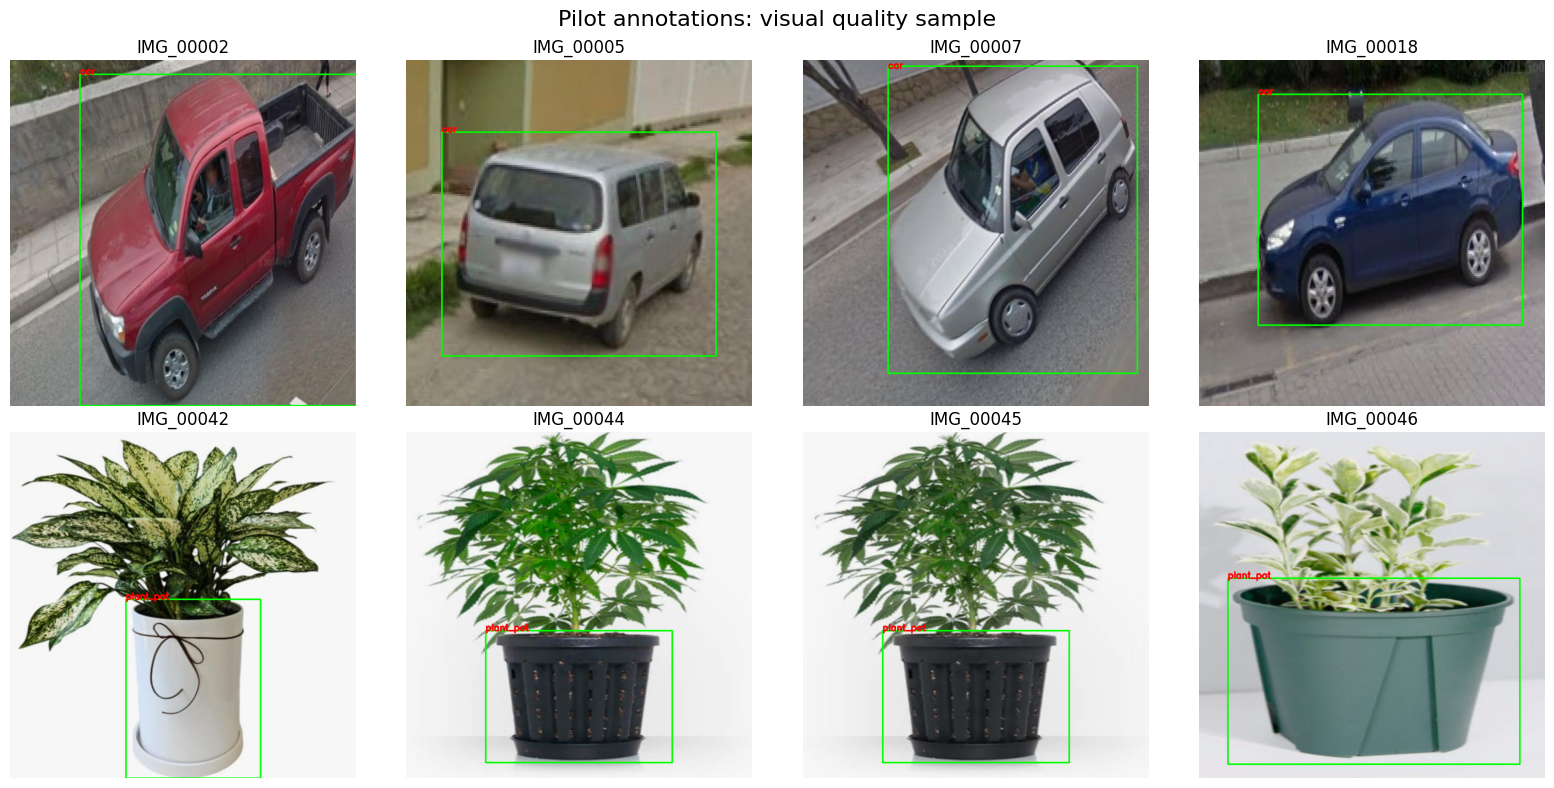

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, image_path in zip(axes.flat, sorted((PILOT_ROOT / 'images' / 'train').glob('*.jpg'))[:8]):
    img = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for line in (PILOT_ROOT / 'labels' / 'train' / f'{image_path.stem}.txt').read_text().splitlines():
        cls, xc, yc, bw, bh = map(float, line.split())
        x1, y1 = int((xc-bw/2)*w), int((yc-bh/2)*h); x2, y2 = int((xc+bw/2)*w), int((yc+bh/2)*h)
        cv2.rectangle(img, (x1,y1), (x2,y2), (0,255,0), 2)
        cv2.putText(img, CLASS_NAMES[int(cls)], (max(0,x1), max(15,y1)), cv2.FONT_HERSHEY_SIMPLEX, .55, (255,0,0), 2)
    ax.imshow(img); ax.set_title(image_path.stem); ax.axis('off')
plt.suptitle('Pilot annotations: visual quality sample', fontsize=16); plt.tight_layout();
annotation_preview = RUNS_ROOT / 'annotation_preview.png'
plt.savefig(annotation_preview, dpi=160, bbox_inches='tight'); plt.show()

## 5. Pretrained baseline

A COCO-pretrained YOLOv8n already recognizes **person, bicycle, car, chair, and potted plant**, but it does not have native classes for **stairs** or **electrical pole**. The baseline is therefore evaluated only on those five compatible classes. Its metrics must not be described as seven-class performance.

In [7]:
baseline_root = DATA_ROOT / 'processed' / 'rod_pilot_coco_baseline'
(baseline_root / 'images' / 'val').mkdir(parents=True, exist_ok=True)
(baseline_root / 'labels' / 'val').mkdir(parents=True, exist_ok=True)
COCO_ID_BY_OLD_ID = {3: 0, 0: 1, 2: 2, 23: 56, 21: 58}
coco_names = YOLO('yolov8n.pt').names
for row in pilot_frames['val'].itertuples(index=False):
    src = PILOT_ROOT / 'images' / 'val' / Path(row.file_name).name
    dst = baseline_root / 'images' / 'val' / src.name
    if not dst.exists():
        try: os.link(src, dst)
        except OSError: shutil.copy2(src, dst)
    lines = []
    for box in row.target_boxes:
        old_id = int(box['class_id'])
        if old_id in COCO_ID_BY_OLD_ID:
            vals = [box['x_center'], box['y_center'], box['width'], box['height']]
            lines.append(f"{COCO_ID_BY_OLD_ID[old_id]} " + ' '.join(f'{float(v):.8f}' for v in vals))
    (baseline_root / 'labels' / 'val' / f'{src.stem}.txt').write_text('\n'.join(lines) + ('\n' if lines else ''), encoding='utf-8')

baseline_yaml = {'path': baseline_root.as_posix(), 'train': 'images/val', 'val': 'images/val', 'names': coco_names}
baseline_yaml_path = baseline_root / 'dataset.yaml'
baseline_yaml_path.write_text(yaml.safe_dump(baseline_yaml, sort_keys=False), encoding='utf-8')
baseline_model = YOLO('yolov8n.pt')
baseline_metrics = baseline_model.val(data=str(baseline_yaml_path), imgsz=512, batch=4, device=0, workers=2, project=str(RUNS_ROOT), name='baseline_coco5', plots=True, verbose=False)
baseline_summary = {'precision': float(baseline_metrics.box.mp), 'recall': float(baseline_metrics.box.mr), 'mAP50': float(baseline_metrics.box.map50), 'mAP50_95': float(baseline_metrics.box.map)}
display(pd.Series(baseline_summary, name='COCO-compatible baseline').to_frame())

Ultralytics 8.3.0  Python-3.10.0 torch-2.0.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)


YOLOv8n summary (fused): 168 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs


val: Scanning C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\data\processed\rod_pilot_coco_baseline\labels\val.cache... 400 images, 76 backgrounds, 0 corrupt: 100%|██████████| 400/400 [00:00<?, ?it/s]

val: Scanning C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\data\processed\rod_pilot_coco_baseline\labels\val.cache... 400 images, 76 backgrounds, 0 corrupt: 100%|██████████| 400/400 [00:00<?, ?it/s]

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95):   0%|          | 0/100 [00:00<?, ?it/s]

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95):   1%|          | 1/100 [00:00<00:48,  2.04it/s]

... (30 outputs left out)

                   all        400        529      0.601      0.543      0.569      0.437


Speed: 0.2ms preprocess, 4.6ms inference, 0.0ms loss, 1.9ms postprocess per image


Results saved to C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\runs\yolov8n_pilot\baseline_coco52


,COCO-compatible baseline
precision,0.600834
recall,0.542538
mAP50,0.568814
mAP50_95,0.437355


## 6. Five-epoch pilot fine-tuning

Fine-tuning begins from the pretrained YOLOv8n weights and adapts the detection head to the seven-class pilot taxonomy. Five epochs are intentionally short: the objective is to verify the end-to-end research pipeline and obtain preliminary measurements within the reporting window.

In [8]:
train_config = {
    'data': str(dataset_yaml_path), 'epochs': 5, 'imgsz': 512, 'batch': 4,
    'device': 0, 'workers': 2, 'seed': SEED, 'deterministic': True,
    'project': str(RUNS_ROOT), 'name': 'finetune_7class_5epoch',
    'exist_ok': True, 'plots': True, 'verbose': True, 'cache': False,
}
(RUNS_ROOT / 'train_config.json').write_text(json.dumps(train_config, indent=2), encoding='utf-8')
model = YOLO('yolov8n.pt')
try:
    training_result = model.train(**train_config)
except torch.cuda.OutOfMemoryError:
    torch.cuda.empty_cache()
    train_config.update({'batch': 2, 'imgsz': 416, 'name': 'finetune_7class_5epoch_fallback'})
    (RUNS_ROOT / 'train_config_fallback.json').write_text(json.dumps(train_config, indent=2), encoding='utf-8')
    model = YOLO('yolov8n.pt')
    training_result = model.train(**train_config)

New https://pypi.org/project/ultralytics/8.4.138 available  Update with 'pip install -U ultralytics'


Ultralytics 8.3.0  Python-3.10.0 torch-2.0.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)


engine\trainer: task=detect, mode=train, model=yolov8n.pt, data=C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\data\processed\rod_pilot_7class\dataset.yaml, epochs=5, time=None, patience=100, batch=4, imgsz=512, save=True, save_period=-1, cache=False, device=0, workers=2, project=C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\runs\yolov8n_pilot, name=finetune_7class_5epoch, exist_ok=True, pretrained=True, optimizer=auto, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False

Overriding model.yaml nc=80 with nc=7



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (4,054 outputs left out)

       electrical_pole         28         29        0.5      0.172      0.181      0.134


             plant_pot         25         37      0.869      0.811      0.914      0.685


Speed: 0.2ms preprocess, 2.3ms inference, 0.0ms loss, 1.4ms postprocess per image


Results saved to C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\runs\yolov8n_pilot\finetune_7class_5epoch


## 7. Validation metrics

Object detection is not adequately represented by ordinary classification accuracy. This notebook reports precision, recall, mAP@0.5, and mAP@0.5–0.95. The confusion matrix and per-class scores reveal which hazards remain difficult.

In [9]:
run_dir = Path(model.trainer.save_dir)
best_weights = run_dir / 'weights' / 'best.pt'
best_model = YOLO(str(best_weights))
final_metrics = best_model.val(data=str(dataset_yaml_path), imgsz=train_config['imgsz'], batch=train_config['batch'], device=0, workers=2, project=str(RUNS_ROOT), name='final_validation', plots=True, verbose=False)
overall = pd.DataFrame([{
    'model': 'fine-tuned YOLOv8n (7 classes)',
    'precision': float(final_metrics.box.mp), 'recall': float(final_metrics.box.mr),
    'mAP@0.5': float(final_metrics.box.map50), 'mAP@0.5:0.95': float(final_metrics.box.map),
}])
display(overall)
per_class = pd.DataFrame({
    'class': CLASS_NAMES,
    'mAP@0.5': final_metrics.box.ap50,
    'mAP@0.5:0.95': final_metrics.box.maps,
})
display(per_class.sort_values('mAP@0.5', ascending=False).reset_index(drop=True))
overall.to_csv(RUNS_ROOT / 'final_overall_metrics.csv', index=False)
per_class.to_csv(RUNS_ROOT / 'final_per_class_metrics.csv', index=False)

Ultralytics 8.3.0  Python-3.10.0 torch-2.0.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)


Model summary (fused): 186 layers, 2,685,733 parameters, 0 gradients, 6.8 GFLOPs


C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\.venv\Lib\site-packages\ultralytics\utils\torch_utils.py:254: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ..\aten\src\ATen\Context.cpp:156.)
  fusedconv.weight.copy_(torch.mm(w_bn, w_conv).view(fusedconv.weight.shape))
C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\.venv\Lib\site-packages\ultralytics\utils\torch_utils.py:259: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministi

val: Scanning C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\data\processed\rod_pilot_7class\labels\val.cache... 400 images, 0 backgrounds, 0 corrupt: 100%|██████████| 400/400 [00:00<?, ?it/s]

val: Scanning C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\data\processed\rod_pilot_7class\labels\val.cache... 400 images, 0 backgrounds, 0 corrupt: 100%|██████████| 400/400 [00:00<?, ?it/s]

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95):   0%|          | 0/100 [00:00<?, ?it/s]

... (28 outputs left out)

Speed: 0.3ms preprocess, 3.9ms inference, 0.0ms loss, 1.0ms postprocess per image


Results saved to C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\runs\yolov8n_pilot\final_validation


,model,precision,recall,mAP@0.5,mAP@0.5:0.95
0,fine-tuned YOLOv8n (7 classes),0.775479,0.626942,0.718899,0.505958


,class,mAP@0.5,mAP@0.5:0.95
0,chair,0.920216,0.673471
1,plant_pot,0.915878,0.689361
2,car,0.824896,0.554000
3,stairs,0.790179,0.532693
4,bicycle,0.720664,0.539643
5,person,0.679511,0.418178
6,electrical_pole,0.180949,0.134361


Results saved to C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\runs\yolov8n_pilot\prediction_examples


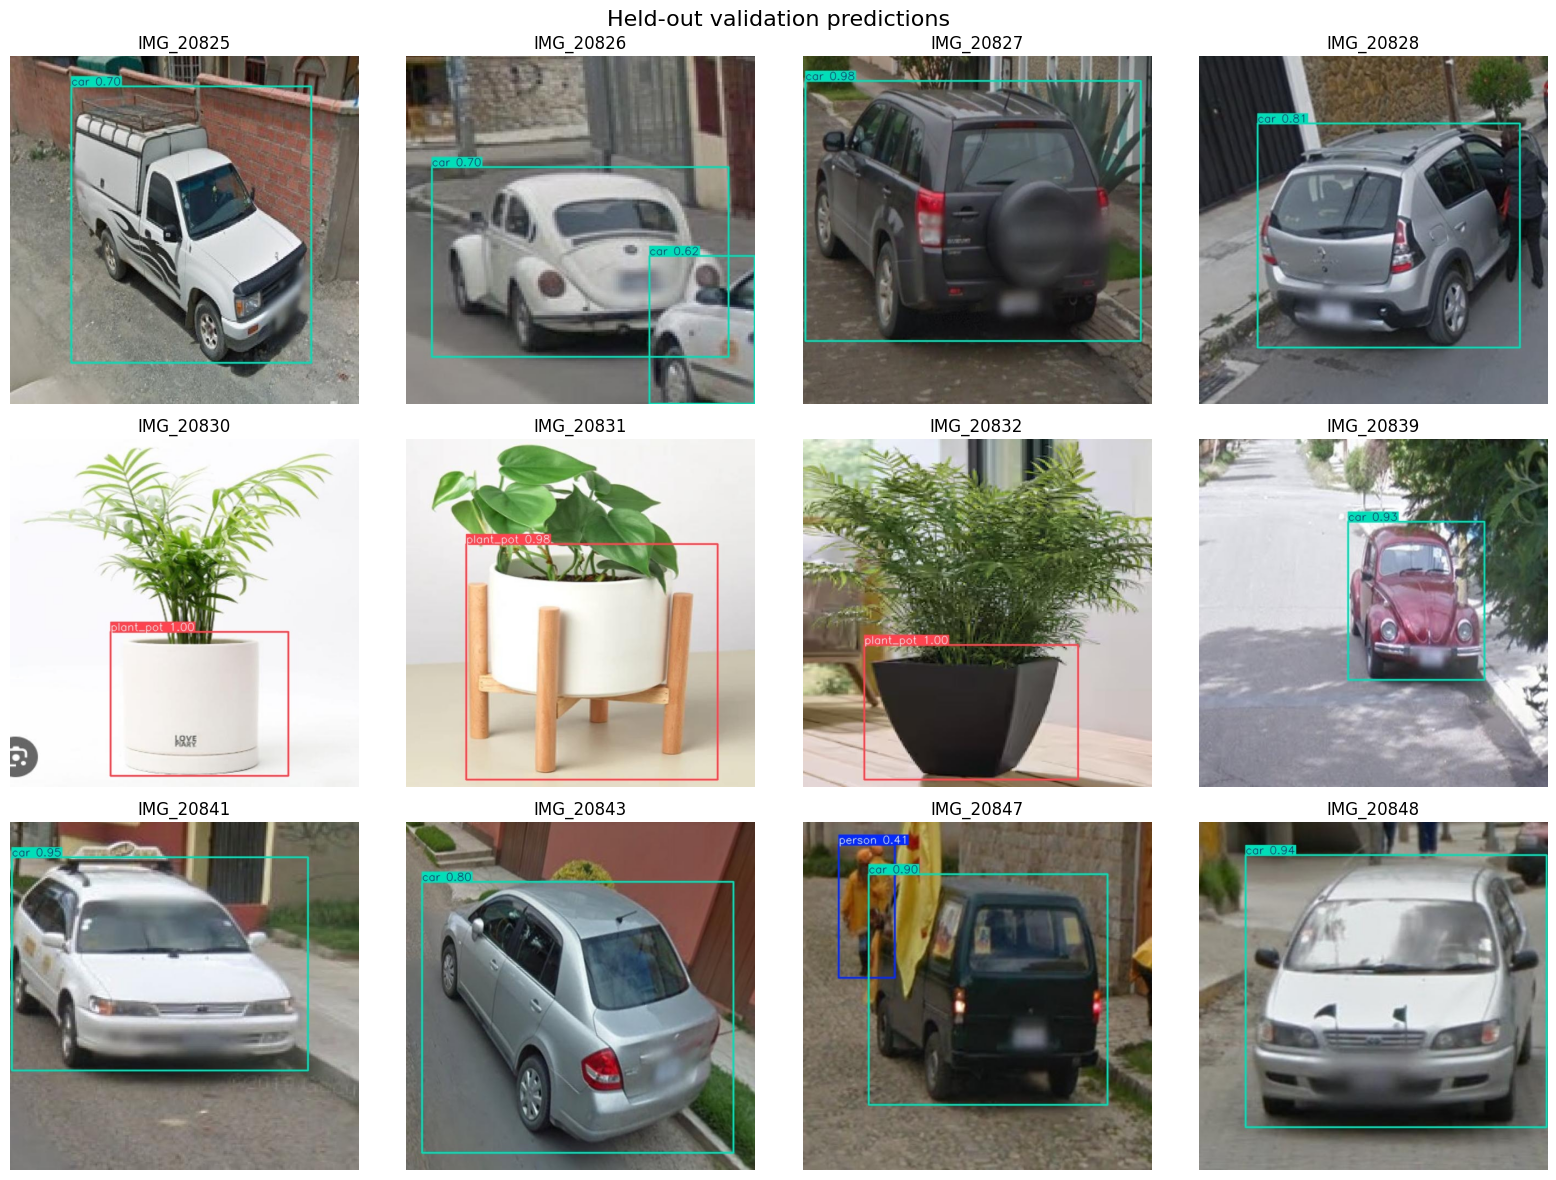

In [10]:
prediction_sources = [str(p) for p in sorted((PILOT_ROOT / 'images' / 'val').glob('*.jpg'))[:12]]
prediction_results = best_model.predict(source=prediction_sources, imgsz=train_config['imgsz'], conf=0.25, device=0, save=True, project=str(RUNS_ROOT), name='prediction_examples', exist_ok=True, verbose=False)
prediction_dir = RUNS_ROOT / 'prediction_examples'
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, path in zip(axes.flat, sorted(prediction_dir.glob('*.jpg'))[:12]):
    ax.imshow(PILImage.open(path)); ax.set_title(path.stem); ax.axis('off')
plt.suptitle('Held-out validation predictions', fontsize=16); plt.tight_layout();
prediction_montage = RUNS_ROOT / 'prediction_montage.png'
plt.savefig(prediction_montage, dpi=160, bbox_inches='tight'); plt.show()

## 8. Interpretation guide for the progress meeting

Use the generated values above; do not memorize or invent a number.

- **Precision:** Of the obstacles announced by the detector, how many were correct?
- **Recall:** Of the labeled obstacles present, how many did the detector find?
- **mAP@0.5:** Detection quality when a predicted box overlaps a ground-truth box by at least 50%.
- **mAP@0.5–0.95:** A stricter summary across several overlap thresholds.
- **Loss curves:** Training signals used to inspect learning behavior; lower loss alone does not prove real-world usefulness.

Suggested explanation: *This pilot demonstrates that the dataset preparation, GPU training, validation, and reporting pipeline works. The metrics are preliminary because the model was trained for only five epochs on a subset. Full training will add campus-specific images and a separate held-out campus test set.*

In [11]:
summary = {
    **environment, 'status': 'PRELIMINARY PILOT — NOT FINAL THESIS RESULT',
    'train_images': int(quality.loc['train', 'images']),
    'validation_images': int(quality.loc['val', 'images']),
    'classes': CLASS_NAMES, 'epochs': int(train_config['epochs']),
    'image_size': int(train_config['imgsz']), 'batch_size': int(train_config['batch']),
    'precision': float(final_metrics.box.mp), 'recall': float(final_metrics.box.mr),
    'mAP50': float(final_metrics.box.map50), 'mAP50_95': float(final_metrics.box.map),
    'best_weights': str(best_weights),
}
summary_path = RUNS_ROOT / 'pilot_summary.json'
summary_path.write_text(json.dumps(summary, indent=2), encoding='utf-8')
display(Markdown(
    f"### Preliminary result\n"
    f"The five-epoch pilot used **{summary['train_images']:,} training** and **{summary['validation_images']:,} validation** images. "
    f"It obtained **precision {summary['precision']:.3f}**, **recall {summary['recall']:.3f}**, "
    f"**mAP@0.5 {summary['mAP50']:.3f}**, and **mAP@0.5–0.95 {summary['mAP50_95']:.3f}**. "
    f"These values are preliminary and must not be generalized to real-world navigation safety."
))
print(f'Saved summary: {summary_path}')

### Preliminary result
The five-epoch pilot used **2,000 training** and **400 validation** images. It obtained **precision 0.775**, **recall 0.627**, **mAP@0.5 0.719**, and **mAP@0.5–0.95 0.506**. These values are preliminary and must not be generalized to real-world navigation safety.

Saved summary: C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\runs\yolov8n_pilot\pilot_summary.json


## 9. Next research steps

1. Audit all upstream licenses before using the complete aggregated dataset.
2. Add and annotate 200–500 local campus images, with consent and privacy safeguards.
3. Extend the taxonomy with doors, tables, and other panel-approved hazards.
4. Run controlled 50–100 epoch experiments and preserve a genuinely held-out campus test set.
5. Compare model size and accuracy after FP16 and INT8 TensorFlow Lite export.
6. Measure inference latency, frame rate, and resource behavior on the target Android device.
7. Treat the application as a supplementary aid and perform any navigation study only under approved safety and ethics procedures.